In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [2]:
df = pd.read_csv("diabetes_prediction_dataset.csv")
df = df.drop_duplicates()
print("Missing values:", df.isna().sum().sum())

Missing values: 0


In [3]:
y = df["diabetes"]
X = pd.get_dummies(df.drop(columns="diabetes"), columns=["gender", "smoking_history"], drop_first=True)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)


In [4]:
models = {
    "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier()),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
}
rows = []
for name, model in models.items():
    s = cross_val_score(model, X_train, y_train, cv=5, n_jobs=-1)
    rows.append([name, s.mean(), s.std()])
print(pd.DataFrame(rows, columns=["Model", "Mean", "Std"]).round(4))

               Model    Mean     Std
0                KNN  0.9584  0.0011
1      Decision Tree  0.9486  0.0017
2      Random Forest  0.9684  0.0010
3  Gradient Boosting  0.9708  0.0015


Best K: 11 | Best max_depth: 2


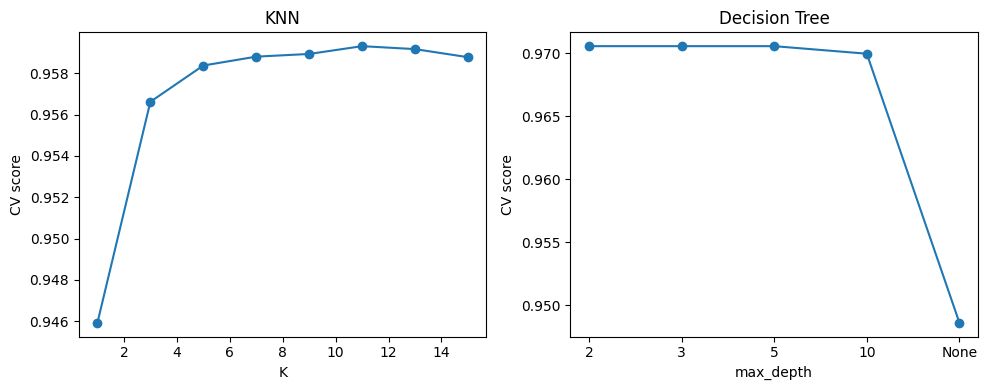

In [5]:
ks = list(range(1, 16, 2))
knn_scores = [cross_val_score(make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k)),
                              X_train, y_train, cv=5, n_jobs=-1).mean() for k in ks]

depths = [2, 3, 5, 10, None]
dt_scores = [cross_val_score(DecisionTreeClassifier(max_depth=d, random_state=42),
                             X_train, y_train, cv=5, n_jobs=-1).mean() for d in depths]

best_k = ks[knn_scores.index(max(knn_scores))]
best_depth = depths[dt_scores.index(max(dt_scores))]
print("Best K:", best_k, "| Best max_depth:", best_depth)

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(ks, knn_scores, marker="o")
plt.xlabel("K"); plt.ylabel("CV score"); plt.title("KNN")
plt.subplot(1, 2, 2)
plt.plot([str(d) for d in depths], dt_scores, marker="o")
plt.xlabel("max_depth"); plt.ylabel("CV score"); plt.title("Decision Tree")
plt.tight_layout()
plt.show()

In [ ]:
rf_grid = GridSearchCV(RandomForestClassifier(random_state=42, n_jobs=-1),
                       {"n_estimators": [50, 100, 200], "max_depth": [3, 5, None]}, cv=5)
rf_grid.fit(X_train, y_train)
print("RF best_params_:", rf_grid.best_params_)
print("RF best_score_:", round(rf_grid.best_score_, 4))
print("Trainings: 9 combinations x 5 folds = 45")

In [7]:
gb_grid = GridSearchCV(GradientBoostingClassifier(random_state=42),
                       {"learning_rate": [0.05, 0.1, 0.2], "n_estimators": [50, 100, 200]},
                       cv=5, n_jobs=-1)
gb_grid.fit(X_train, y_train)
print("GB best_params_:", gb_grid.best_params_)
print("GB best_score_:", round(gb_grid.best_score_, 4))
print("RF vs GB (CV):", round(rf_grid.best_score_, 4), "vs", round(gb_grid.best_score_, 4))

GB best_params_: {'learning_rate': 0.1, 'n_estimators': 100}
GB best_score_: 0.9708
RF vs GB (CV): 0.9706 vs 0.9708


In [8]:
tuned = {
    "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=best_k)),
    "Decision Tree": DecisionTreeClassifier(max_depth=best_depth, random_state=42),
    "Random Forest": rf_grid.best_estimator_,
    "Gradient Boosting": gb_grid.best_estimator_,
}
rows = []
for name, model in tuned.items():
    model.fit(X_train, y_train)
    tr, te = model.score(X_train, y_train), model.score(X_test, y_test)
    rows.append([name, tr, te, tr - te])
print(pd.DataFrame(rows, columns=["Model", "Train score", "Test score", "Gap"]).round(4))

               Model  Train score  Test score     Gap
0                KNN       0.9635      0.9600  0.0035
1      Decision Tree       0.9706      0.9716 -0.0011
2      Random Forest       0.9706      0.9716 -0.0011
3  Gradient Boosting       0.9712      0.9718 -0.0006


In [9]:
final = rf_grid.best_estimator_ if rf_grid.best_score_ >= gb_grid.best_score_ else gb_grid.best_estimator_
pred = final.predict(X_test)
print("Accuracy:", round(accuracy_score(y_test, pred), 4))
print(confusion_matrix(y_test, pred))
print(classification_report(y_test, pred))

Accuracy: 0.9718
[[17518    16]
 [  526  1170]]
              precision    recall  f1-score   support

           0       0.97      1.00      0.98     17534
           1       0.99      0.69      0.81      1696

    accuracy                           0.97     19230
   macro avg       0.98      0.84      0.90     19230
weighted avg       0.97      0.97      0.97     19230

